In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv(r"C:\Users\Nishant\OneDrive\Documents\IndusSync\Data\Thales_Group_Manufacturing.csv")

In [3]:
X = df[[
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Error_Rate_%",
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW"
]]

y = df["Production_Speed_units_per_hr"]

In [4]:
print("Input data shape:", X.shape)
print("Output data shape:", y.shape)

print("\nInput variables:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input data shape: (100000, 6)
Output data shape: (100000,)

Input variables:
   Network_Latency_ms  Packet_Loss_%  Error_Rate_%  Temperature_C  \
0              10.651          0.208        14.965         74.138   
1              29.112          2.228         7.678         84.265   
2              18.357          1.639         8.198         44.280   
3              29.154          1.161         2.741         40.569   
4              34.029          4.797        12.101         75.064   

   Vibration_Hz  Power_Consumption_kW  
0         3.501                 8.612  
1         3.356                 2.269  
2         2.080                 6.144  
3         0.298                 4.068  
4         0.346                 6.226  

Target variable:
0    477.657
1    398.175
2    108.075
3    329.579
4    159.114
Name: Production_Speed_units_per_hr, dtype: float64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 80000
Testing records: 20000


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 80000
Testing records: 20000


In [7]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [8]:
linear_predictions = linear_model.predict(X_test)

print("Actual Production Speed:")
print(y_test.head(10).values)

print("\nPredicted Production Speed:")
print(linear_predictions[:10])

Actual Production Speed:
[361.551  83.197 347.989 189.248  87.958 218.053 431.911 216.375 280.698
 470.286]

Predicted Production Speed:
[277.50322236 275.21318534 276.14336203 276.09681771 274.88212709
 276.01476261 274.56785482 274.20772183 275.89196781 273.95897069]


In [9]:
mae = mean_absolute_error(y_test, linear_predictions)

mse = mean_squared_error(y_test, linear_predictions)

r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 112.8977868222187
MSE: 16968.04731588473
R2 Score: -0.0001122315369950222


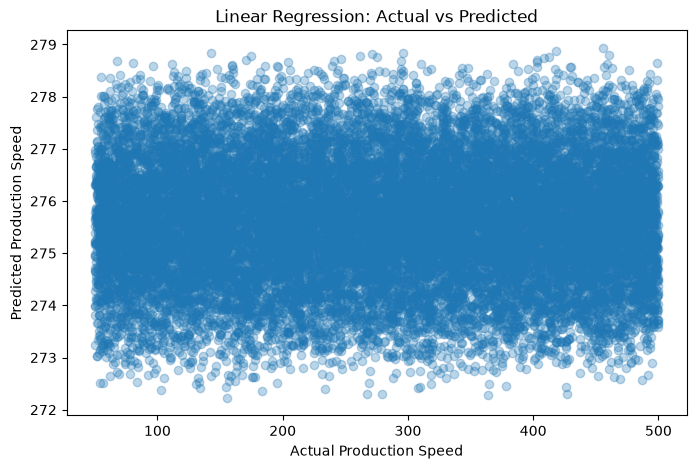

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, linear_predictions, alpha=0.3)

plt.xlabel("Actual Production Speed")
plt.ylabel("Predicted Production Speed")

plt.title("Linear Regression: Actual vs Predicted")

plt.show()

In [11]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [12]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [13]:
rf_predictions = random_forest_model.predict(X_test)

print("Actual Production Speed:")
print(y_test.head(10).values)

print("\nRandom Forest Predictions:")
print(rf_predictions[:10])

Actual Production Speed:
[361.551  83.197 347.989 189.248  87.958 218.053 431.911 216.375 280.698
 470.286]

Random Forest Predictions:
[274.58321 277.13117 296.72733 323.48995 256.50958 259.7658  264.3668
 254.65023 270.36059 304.61764]


In [14]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_mse = mean_squared_error(y_test, rf_predictions)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")

print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("R2 Score:", rf_r2)

Random Forest Results
MAE: 113.985577693
MSE: 17449.343186408038
R2 Score: -0.028480250445569455


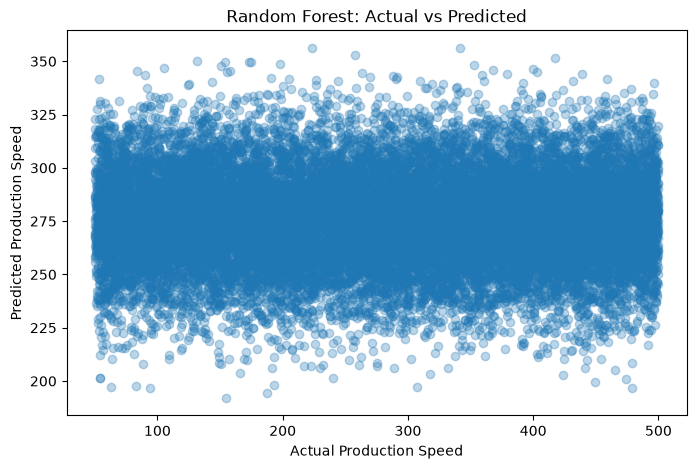

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_predictions, alpha=0.3)

plt.xlabel("Actual Production Speed")
plt.ylabel("Predicted Production Speed")

plt.title("Random Forest: Actual vs Predicted")

plt.show()

In [16]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "MSE": [
        mse,
        rf_mse
    ],
    "R2 Score": [
        r2,
        rf_r2
    ]
})

print(model_comparison)

               Model         MAE           MSE  R2 Score
0  Linear Regression  112.897787  16968.047316 -0.000112
1      Random Forest  113.985578  17449.343186 -0.028480


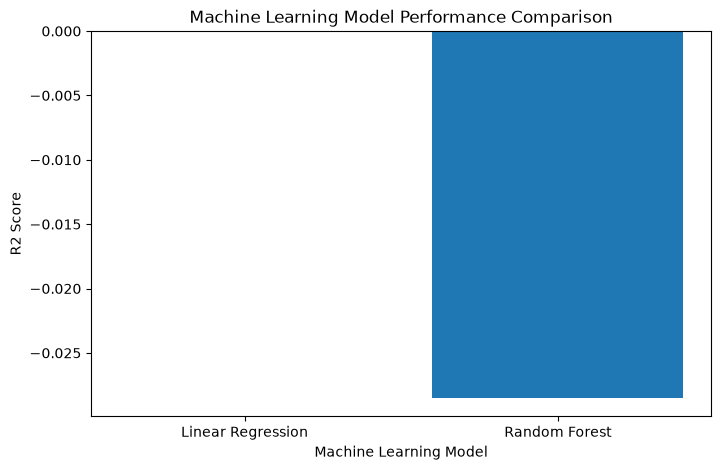

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["R2 Score"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")

plt.title("Machine Learning Model Performance Comparison")

plt.show()

In [18]:
if rf_r2 > r2:
    print("Random Forest performed better.")
elif r2 > rf_r2:
    print("Linear Regression performed better.")
else:
    print("Both models performed equally.")

Linear Regression performed better.


In [19]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                Feature  Importance
2          Error_Rate_%    0.168395
3         Temperature_C    0.168359
0    Network_Latency_ms    0.167266
5  Power_Consumption_kW    0.167071
4          Vibration_Hz    0.164595
1         Packet_Loss_%    0.164314


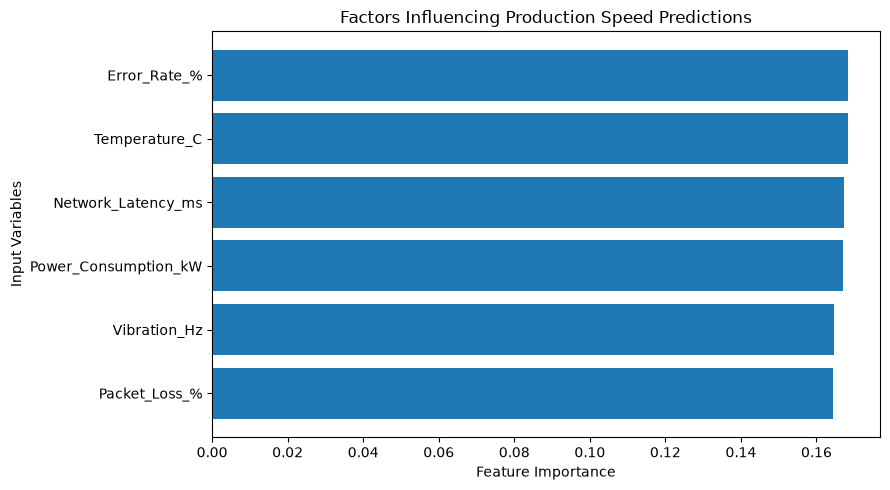

In [20]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Input Variables")

plt.title("Factors Influencing Production Speed Predictions")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [21]:
X_defect = df[[
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Error_Rate_%",
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW"
]]

y_defect = df["Quality_Control_Defect_Rate_%"]

In [22]:
print("Input data:", X_defect.shape)
print("Target data:", y_defect.shape)

print(X_defect.head())
print(y_defect.head())

Input data: (100000, 6)
Target data: (100000,)
   Network_Latency_ms  Packet_Loss_%  Error_Rate_%  Temperature_C  \
0              10.651          0.208        14.965         74.138   
1              29.112          2.228         7.678         84.265   
2              18.357          1.639         8.198         44.280   
3              29.154          1.161         2.741         40.569   
4              34.029          4.797        12.101         75.064   

   Vibration_Hz  Power_Consumption_kW  
0         3.501                 8.612  
1         3.356                 2.269  
2         2.080                 6.144  
3         0.298                 4.068  
4         0.346                 6.226  
0    7.751
1    4.989
2    0.457
3    4.583
4    2.288
Name: Quality_Control_Defect_Rate_%, dtype: float64


In [23]:
X_train_defect, X_test_defect, y_train_defect, y_test_defect = train_test_split(
    X_defect,
    y_defect,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train_defect))
print("Testing records:", len(X_test_defect))

Training records: 80000
Testing records: 20000


In [24]:
linear_defect_model = LinearRegression()

print("Linear Regression model created!")

Linear Regression model created!


In [25]:
linear_defect_model.fit(X_train_defect, y_train_defect)

print("Linear Regression training completed!")

Linear Regression training completed!


In [26]:
linear_defect_predictions = linear_defect_model.predict(X_test_defect)

print("Actual Defect Rates:")
print(y_test_defect.head(10).values)

print("\nPredicted Defect Rates:")
print(linear_defect_predictions[:10])

Actual Defect Rates:
[9.097 2.777 8.418 6.969 7.011 3.664 5.981 2.723 1.886 8.547]

Predicted Defect Rates:
[5.01503756 5.03052501 5.05468777 5.03514619 5.00570276 5.00100324
 5.00043687 4.97765931 5.03324103 4.95489054]


In [27]:
defect_mae = mean_absolute_error(
    y_test_defect,
    linear_defect_predictions
)

defect_mse = mean_squared_error(
    y_test_defect,
    linear_defect_predictions
)

defect_r2 = r2_score(
    y_test_defect,
    linear_defect_predictions
)

print("Linear Regression Defect Prediction Results")

print("MAE:", defect_mae)
print("MSE:", defect_mse)
print("R2 Score:", defect_r2)

Linear Regression Defect Prediction Results
MAE: 2.5092802678120076
MSE: 8.378656621173862
R2 Score: -0.00015529375399436773


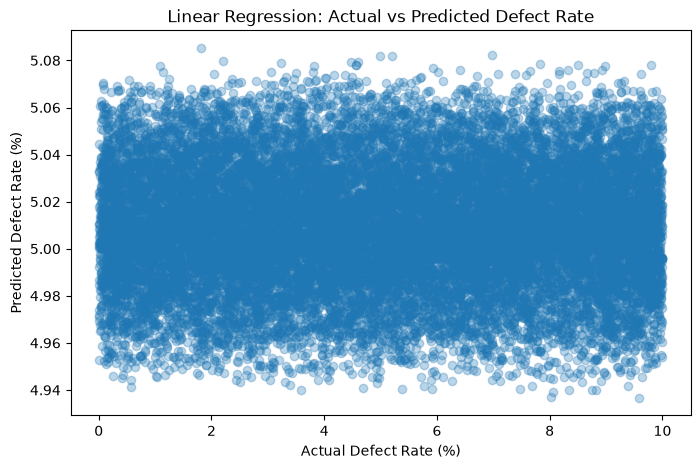

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_defect,
    linear_defect_predictions,
    alpha=0.3
)

plt.xlabel("Actual Defect Rate (%)")
plt.ylabel("Predicted Defect Rate (%)")

plt.title("Linear Regression: Actual vs Predicted Defect Rate")

plt.show()

In [29]:
rf_defect_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created!")

Random Forest model created!


In [30]:
rf_defect_model.fit(X_train_defect, y_train_defect)

print("Random Forest training completed!")

Random Forest training completed!


In [31]:
rf_defect_predictions = rf_defect_model.predict(X_test_defect)

print("Actual Defect Rates:")
print(y_test_defect.head(10).values)

print("\nRandom Forest Predictions:")
print(rf_defect_predictions[:10])

Actual Defect Rates:
[9.097 2.777 8.418 6.969 7.011 3.664 5.981 2.723 1.886 8.547]

Random Forest Predictions:
[6.19908 5.09121 4.58731 5.38299 5.45509 3.90806 3.76668 5.83405 5.42604
 4.77563]


In [32]:
rf_defect_mae = mean_absolute_error(
    y_test_defect,
    rf_defect_predictions
)

rf_defect_mse = mean_squared_error(
    y_test_defect,
    rf_defect_predictions
)

rf_defect_r2 = r2_score(
    y_test_defect,
    rf_defect_predictions
)

print("Random Forest Defect Prediction Results")

print("MAE:", rf_defect_mae)
print("MSE:", rf_defect_mse)
print("R2 Score:", rf_defect_r2)

Random Forest Defect Prediction Results
MAE: 2.5332187695
MSE: 8.615894435561565
R2 Score: -0.02847423158215001


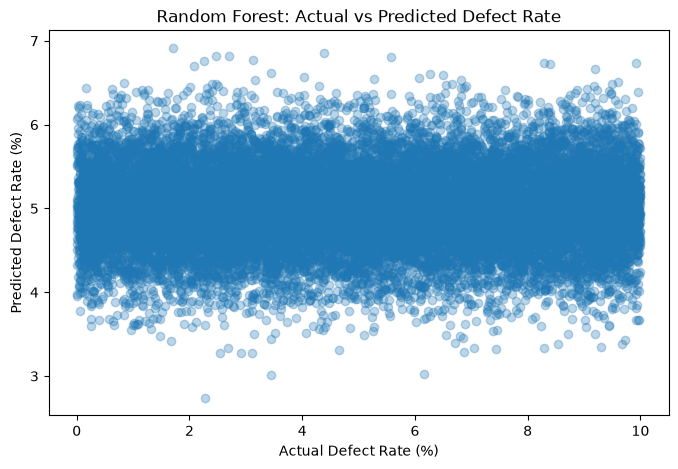

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_defect,
    rf_defect_predictions,
    alpha=0.3
)

plt.xlabel("Actual Defect Rate (%)")
plt.ylabel("Predicted Defect Rate (%)")

plt.title("Random Forest: Actual vs Predicted Defect Rate")

plt.show()

In [34]:
defect_model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        defect_mae,
        rf_defect_mae
    ],
    "MSE": [
        defect_mse,
        rf_defect_mse
    ],
    "R2 Score": [
        defect_r2,
        rf_defect_r2
    ]
})

print(defect_model_comparison)

               Model       MAE       MSE  R2 Score
0  Linear Regression  2.509280  8.378657 -0.000155
1      Random Forest  2.533219  8.615894 -0.028474


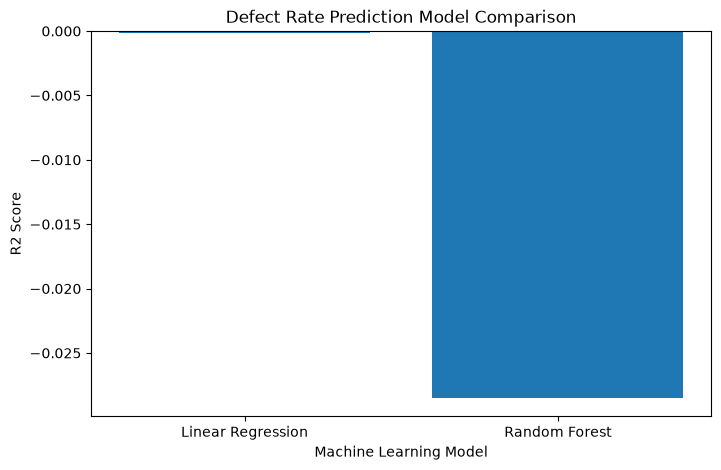

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    defect_model_comparison["Model"],
    defect_model_comparison["R2 Score"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")

plt.title("Defect Rate Prediction Model Comparison")

plt.show()

In [36]:
if rf_defect_r2 > defect_r2:
    print("Random Forest performed better.")
elif defect_r2 > rf_defect_r2:
    print("Linear Regression performed better.")
else:
    print("Both models performed equally.")

Linear Regression performed better.


In [37]:
defect_importance = pd.DataFrame({
    "Feature": X_defect.columns,
    "Importance": rf_defect_model.feature_importances_
})

defect_importance = defect_importance.sort_values(
    by="Importance",
    ascending=False
)

print(defect_importance)

                Feature  Importance
0    Network_Latency_ms    0.169027
3         Temperature_C    0.168317
2          Error_Rate_%    0.166831
5  Power_Consumption_kW    0.166069
1         Packet_Loss_%    0.164993
4          Vibration_Hz    0.164764


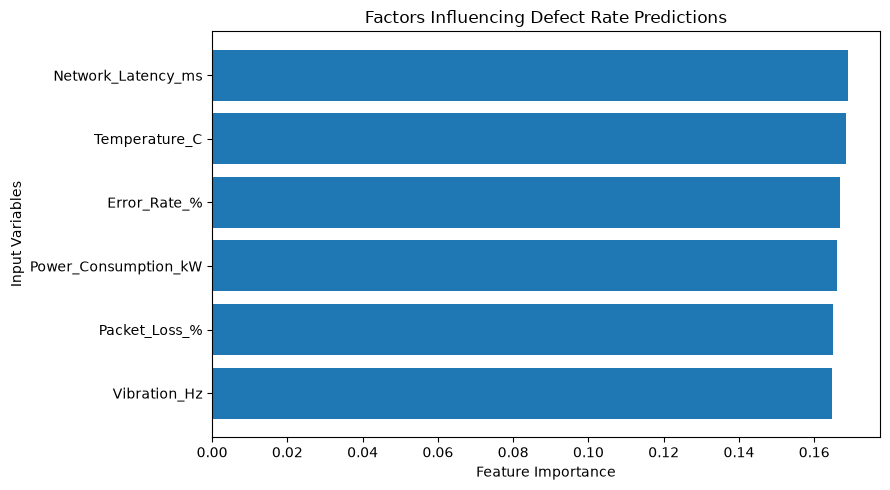

In [38]:
plt.figure(figsize=(9, 5))

plt.barh(
    defect_importance["Feature"],
    defect_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Input Variables")

plt.title("Factors Influencing Defect Rate Predictions")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [39]:
all_model_results = pd.DataFrame({
    "Prediction Target": [
        "Production Speed",
        "Production Speed",
        "Defect Rate",
        "Defect Rate"
    ],
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [mae, rf_mae, defect_mae, rf_defect_mae],
    "MSE": [mse, rf_mse, defect_mse, rf_defect_mse],
    "R2 Score": [r2, rf_r2, defect_r2, rf_defect_r2]
})

print(all_model_results.round(4))

  Prediction Target              Model       MAE         MSE  R2 Score
0  Production Speed  Linear Regression  112.8978  16968.0473   -0.0001
1  Production Speed      Random Forest  113.9856  17449.3432   -0.0285
2       Defect Rate  Linear Regression    2.5093      8.3787   -0.0002
3       Defect Rate      Random Forest    2.5332      8.6159   -0.0285


In [40]:
best_models = all_model_results.loc[
    all_model_results.groupby("Prediction Target")["R2 Score"].idxmax()
]

print("Best Model for Each Prediction Task:")
print(best_models.round(4))

Best Model for Each Prediction Task:
  Prediction Target              Model       MAE         MSE  R2 Score
2       Defect Rate  Linear Regression    2.5093      8.3787   -0.0002
0  Production Speed  Linear Regression  112.8978  16968.0473   -0.0001


In [41]:
all_model_results.to_csv("overall_machine_learning_results.csv", index=False)

best_models.to_csv("best_machine_learning_models.csv", index=False)

print("Machine learning results saved successfully.")

Machine learning results saved successfully.


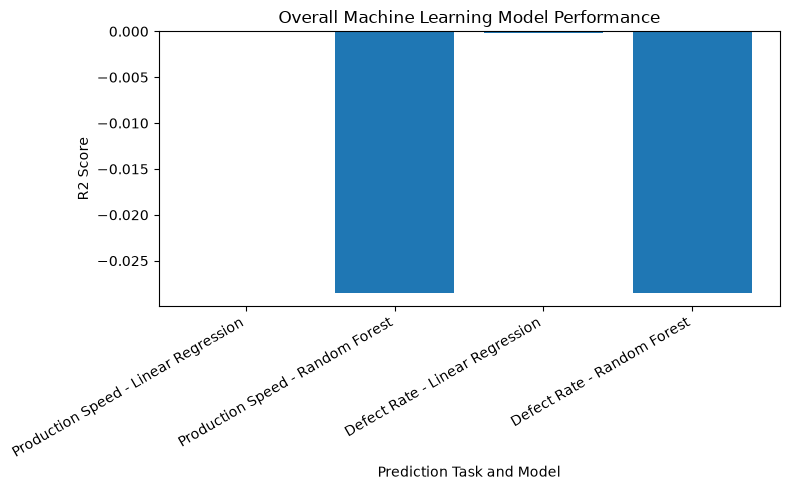

In [42]:
plt.figure(figsize=(8, 5))

plt.bar(
    all_model_results["Prediction Target"] + " - " + all_model_results["Model"],
    all_model_results["R2 Score"]
)

plt.title("Overall Machine Learning Model Performance")
plt.xlabel("Prediction Task and Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [43]:
machine_counts = df["Machine_ID"].value_counts()

print("Total Number of Machines:", df["Machine_ID"].nunique())
print("Minimum Records per Machine:", machine_counts.min())
print("Maximum Records per Machine:", machine_counts.max())

Total Number of Machines: 50
Minimum Records per Machine: 1906
Maximum Records per Machine: 2092


In [44]:
X = df.drop(columns=["Production_Speed_units_per_hr", "Quality_Control_Defect_Rate_%"])

groups = df["Machine_ID"]

In [45]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [46]:
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_index, test_index = next(split.split(X, groups=groups))

X_train = X.iloc[train_index].drop(columns=["Machine_ID"])
X_test = X.iloc[test_index].drop(columns=["Machine_ID"])

groups_train = groups.iloc[train_index]
groups_test = groups.iloc[test_index]

print("Training Machines:", groups_train.nunique())
print("Testing Machines:", groups_test.nunique())

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Machines: 40
Testing Machines: 10
Training Records: 80290
Testing Records: 19710


In [47]:
common_machines = set(groups_train.unique()) & set(groups_test.unique())

print("Machines appearing in both datasets:", len(common_machines))

if len(common_machines) == 0:
    print("Success! No machine overlap.")
else:
    print("Warning! Some machines appear in both datasets.")

Machines appearing in both datasets: 0
Success! No machine overlap.


In [48]:
y_speed = df["Production_Speed_units_per_hr"]

y_speed_train = y_speed.iloc[train_index]
y_speed_test = y_speed.iloc[test_index]

y_defect = df["Quality_Control_Defect_Rate_%"]

y_defect_train = y_defect.iloc[train_index]
y_defect_test = y_defect.iloc[test_index]

In [49]:
print("Columns containing text data:")

print(df.select_dtypes(include=["object"]).columns.tolist())

print("\nAll dataset columns:")

print(df.columns.tolist())

Columns containing text data:
['Date', 'Timestamp', 'Operation_Mode', 'Efficiency_Status']

All dataset columns:
['Date', 'Timestamp', 'Machine_ID', 'Operation_Mode', 'Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score', 'Error_Rate_%', 'Efficiency_Status']


C:\Users\Nishant\AppData\Local\Temp\ipykernel_32760\1899361833.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include=["object"]).columns.tolist())


In [50]:
X_unseen = df.drop(columns=[
    "Date",
    "Timestamp",
    "Operation_Mode",
    "Efficiency_Status",
    "Production_Speed_units_per_hr",
    "Quality_Control_Defect_Rate_%"
])

groups = df["Machine_ID"]

print("Input features prepared successfully.")
print("Number of input features:", X_unseen.shape[1])
print("Number of machines:", groups.nunique())

Input features prepared successfully.
Number of input features: 8
Number of machines: 50


In [51]:
split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_index, test_index = next(
    split.split(X_unseen, groups=groups)
)

X_train = X_unseen.iloc[train_index].drop(columns=["Machine_ID"])
X_test = X_unseen.iloc[test_index].drop(columns=["Machine_ID"])

groups_train = groups.iloc[train_index]
groups_test = groups.iloc[test_index]

print("Training machines:", groups_train.nunique())
print("Testing machines:", groups_test.nunique())

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training machines: 40
Testing machines: 10
Training records: 80290
Testing records: 19710


In [52]:
common_machines = set(groups_train.unique()) & set(groups_test.unique())

print("Machines appearing in both datasets:", len(common_machines))

Machines appearing in both datasets: 0


In [53]:
y_speed = df["Production_Speed_units_per_hr"]
y_defect = df["Quality_Control_Defect_Rate_%"]

y_speed_train = y_speed.iloc[train_index]
y_speed_test = y_speed.iloc[test_index]

y_defect_train = y_defect.iloc[train_index]
y_defect_test = y_defect.iloc[test_index]

print("Prediction targets prepared successfully.")

Prediction targets prepared successfully.


In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr_speed_unseen = LinearRegression()
lr_speed_unseen.fit(X_train, y_speed_train)

lr_speed_predictions = lr_speed_unseen.predict(X_test)


rf_speed_unseen = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_speed_unseen.fit(X_train, y_speed_train)

rf_speed_predictions = rf_speed_unseen.predict(X_test)

print("Production Speed models trained successfully.")

Production Speed models trained successfully.


In [55]:
print("Linear Regression")
print("MAE:", mean_absolute_error(y_speed_test, lr_speed_predictions))
print("MSE:", mean_squared_error(y_speed_test, lr_speed_predictions))
print("R2 Score:", r2_score(y_speed_test, lr_speed_predictions))

print("\nRandom Forest")
print("MAE:", mean_absolute_error(y_speed_test, rf_speed_predictions))
print("MSE:", mean_squared_error(y_speed_test, rf_speed_predictions))
print("R2 Score:", r2_score(y_speed_test, rf_speed_predictions))

Linear Regression
MAE: 113.28799624070572
MSE: 17039.142049388727
R2 Score: 0.00017711574614076575

Random Forest
MAE: 114.16729204566211
MSE: 17421.44168324585
R2 Score: -0.02225546457182981


In [56]:
lr_defect_unseen = LinearRegression()

lr_defect_unseen.fit(X_train, y_defect_train)

lr_defect_predictions = lr_defect_unseen.predict(X_test)


rf_defect_unseen = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_defect_unseen.fit(X_train, y_defect_train)

rf_defect_predictions = rf_defect_unseen.predict(X_test)

print("Defect Rate models trained successfully.")

Defect Rate models trained successfully.


In [57]:
print("Linear Regression")
print("MAE:", mean_absolute_error(y_defect_test, lr_defect_predictions))
print("MSE:", mean_squared_error(y_defect_test, lr_defect_predictions))
print("R2 Score:", r2_score(y_defect_test, rf_defect_predictions))

print("\nRandom Forest")
print("MAE:", mean_absolute_error(y_defect_test, rf_defect_predictions))
print("MSE:", mean_squared_error(y_defect_test, rf_defect_predictions))
print("R2 Score:", r2_score(y_defect_test, rf_defect_predictions))

Linear Regression
MAE: 2.4984672302841804
MSE: 8.308886415217987
R2 Score: -0.027711330000356416

Random Forest
MAE: 2.5198849523084728
MSE: 8.537259160333805
R2 Score: -0.027711330000356416


In [58]:
unseen_machine_results = pd.DataFrame({
    "Prediction Target": [
        "Production Speed",
        "Production Speed",
        "Defect Rate",
        "Defect Rate"
    ],
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_speed_test, lr_speed_predictions),
        mean_absolute_error(y_speed_test, rf_speed_predictions),
        mean_absolute_error(y_defect_test, lr_defect_predictions),
        mean_absolute_error(y_defect_test, rf_defect_predictions)
    ],
    "MSE": [
        mean_squared_error(y_speed_test, lr_speed_predictions),
        mean_squared_error(y_speed_test, rf_speed_predictions),
        mean_squared_error(y_defect_test, lr_defect_predictions),
        mean_squared_error(y_defect_test, rf_defect_predictions)
    ],
    "R2 Score": [
        r2_score(y_speed_test, lr_speed_predictions),
        r2_score(y_speed_test, rf_speed_predictions),
        r2_score(y_defect_test, lr_defect_predictions),
        r2_score(y_defect_test, rf_defect_predictions)
    ]
})

print(unseen_machine_results.round(4))

  Prediction Target              Model       MAE         MSE  R2 Score
0  Production Speed  Linear Regression  113.2880  17039.1420    0.0002
1  Production Speed      Random Forest  114.1673  17421.4417   -0.0223
2       Defect Rate  Linear Regression    2.4985      8.3089   -0.0002
3       Defect Rate      Random Forest    2.5199      8.5373   -0.0277


In [59]:
best_unseen_models = unseen_machine_results.loc[
    unseen_machine_results.groupby("Prediction Target")["R2 Score"].idxmax()
]

print("Best Models on Unseen Machines:")
print(best_unseen_models.round(4))

Best Models on Unseen Machines:
  Prediction Target              Model       MAE         MSE  R2 Score
2       Defect Rate  Linear Regression    2.4985      8.3089   -0.0002
0  Production Speed  Linear Regression  113.2880  17039.1420    0.0002


In [60]:
unseen_machine_results.to_csv("unseen_machine_results.csv", index=False)

best_unseen_models.to_csv("best_unseen_machine_models.csv", index=False)

print("Unseen machine results saved successfully.")

Unseen machine results saved successfully.


In [61]:
comparison_results = pd.concat(
    [
        all_model_results.assign(Test_Type="Random Split"),
        unseen_machine_results.assign(Test_Type="Unseen Machines")
    ],
    ignore_index=True
)

print(comparison_results.round(4))

  Prediction Target              Model       MAE         MSE  R2 Score  \
0  Production Speed  Linear Regression  112.8978  16968.0473   -0.0001   
1  Production Speed      Random Forest  113.9856  17449.3432   -0.0285   
2       Defect Rate  Linear Regression    2.5093      8.3787   -0.0002   
3       Defect Rate      Random Forest    2.5332      8.6159   -0.0285   
4  Production Speed  Linear Regression  113.2880  17039.1420    0.0002   
5  Production Speed      Random Forest  114.1673  17421.4417   -0.0223   
6       Defect Rate  Linear Regression    2.4985      8.3089   -0.0002   
7       Defect Rate      Random Forest    2.5199      8.5373   -0.0277   

         Test_Type  
0     Random Split  
1     Random Split  
2     Random Split  
3     Random Split  
4  Unseen Machines  
5  Unseen Machines  
6  Unseen Machines  
7  Unseen Machines  


In [62]:
comparison_results.to_csv(
    "random_vs_unseen_machine_comparison.csv",
    index=False
)

print("Final comparison saved successfully.")

Final comparison saved successfully.


In [63]:
print("PHASE 5.12 - UNSEEN MACHINE VALIDATION")
print("---------------------------------------")

print("Total Machines:", df["Machine_ID"].nunique())

print("Training Machines:", groups_train.nunique())

print("Testing Machines:", groups_test.nunique())

print("Machine Overlap:", len(common_machines))

print("\nBest Models:")
print(best_unseen_models.round(4))

print("\nConclusion:")
print("Both prediction tasks show very low R2 scores.")
print("Further feature analysis and model improvement are required.")

PHASE 5.12 - UNSEEN MACHINE VALIDATION
---------------------------------------
Total Machines: 50
Training Machines: 40
Testing Machines: 10
Machine Overlap: 0

Best Models:
  Prediction Target              Model       MAE         MSE  R2 Score
2       Defect Rate  Linear Regression    2.4985      8.3089   -0.0002
0  Production Speed  Linear Regression  113.2880  17039.1420    0.0002

Conclusion:
Both prediction tasks show very low R2 scores.
Further feature analysis and model improvement are required.


In [64]:
best_unseen_models.to_csv(
    "phase_5_12_validation_summary.csv",
    index=False
)

print("Phase 5.12 summary saved successfully.")

Phase 5.12 summary saved successfully.


In [65]:
# Operation Mode Analysis

operation_analysis = df.groupby("Operation_Mode").agg({
    "Network_Latency_ms": "mean",
    "Packet_Loss_%": "mean",
    "Production_Speed_units_per_hr": "mean",
    "Quality_Control_Defect_Rate_%": "mean",
    "Error_Rate_%": "mean"
})

print(operation_analysis.round(2))

                Network_Latency_ms  Packet_Loss_%  \
Operation_Mode                                      
Active                       25.54           2.49   
Idle                         25.64           2.50   
Maintenance                  25.50           2.48   

                Production_Speed_units_per_hr  Quality_Control_Defect_Rate_%  \
Operation_Mode                                                                 
Active                                 276.20                           5.01   
Idle                                   274.13                           5.01   
Maintenance                            277.54                           5.00   

                Error_Rate_%  
Operation_Mode                
Active                  7.49  
Idle                    7.52  
Maintenance             7.54  


In [66]:
# Network Impact Across Operation Modes

for mode in df["Operation_Mode"].unique():

    mode_data = df[df["Operation_Mode"] == mode]

    print("\nOperation Mode:", mode)

    print(mode_data[[
        "Network_Latency_ms",
        "Packet_Loss_%",
        "Production_Speed_units_per_hr",
        "Quality_Control_Defect_Rate_%",
        "Error_Rate_%"
    ]].corr().round(3))


Operation Mode: Idle
                               Network_Latency_ms  Packet_Loss_%  \
Network_Latency_ms                          1.000         -0.017   
Packet_Loss_%                              -0.017          1.000   
Production_Speed_units_per_hr              -0.014         -0.011   
Quality_Control_Defect_Rate_%               0.007          0.002   
Error_Rate_%                               -0.006          0.000   

                               Production_Speed_units_per_hr  \
Network_Latency_ms                                    -0.014   
Packet_Loss_%                                         -0.011   
Production_Speed_units_per_hr                          1.000   
Quality_Control_Defect_Rate_%                          0.007   
Error_Rate_%                                           0.015   

                               Quality_Control_Defect_Rate_%  Error_Rate_%  
Network_Latency_ms                                     0.007        -0.006  
Packet_Loss_%                 

In [67]:
# Compare network impact across operation modes

for mode in df["Operation_Mode"].unique():

    mode_data = df[df["Operation_Mode"] == mode]

    print("\n", mode)

    print("Latency vs Production Speed:",
          round(mode_data["Network_Latency_ms"].corr(
              mode_data["Production_Speed_units_per_hr"]), 4))

    print("Packet Loss vs Production Speed:",
          round(mode_data["Packet_Loss_%"].corr(
              mode_data["Production_Speed_units_per_hr"]), 4))

    print("Latency vs Defect Rate:",
          round(mode_data["Network_Latency_ms"].corr(
              mode_data["Quality_Control_Defect_Rate_%"]), 4))

    print("Packet Loss vs Error Rate:",
          round(mode_data["Packet_Loss_%"].corr(
              mode_data["Error_Rate_%"]), 4))


 Idle
Latency vs Production Speed: -0.0136
Packet Loss vs Production Speed: -0.0114
Latency vs Defect Rate: 0.0071
Packet Loss vs Error Rate: 0.0004

 Active
Latency vs Production Speed: 0.0016
Packet Loss vs Production Speed: -0.0072
Latency vs Defect Rate: -0.0086
Packet Loss vs Error Rate: -0.0025

 Maintenance
Latency vs Production Speed: 0.0063
Packet Loss vs Production Speed: 0.0022
Latency vs Defect Rate: 0.0025
Packet Loss vs Error Rate: -0.0076


In [68]:
# Network Quality Segmentation

# Calculate percentage ranks
df["Latency_Rank"] = df["Network_Latency_ms"].rank(pct=True)

df["Packet_Loss_Rank"] = df["Packet_Loss_%"].rank(pct=True)

# Calculate combined network degradation score
df["Network_Degradation_Score"] = (
    df["Latency_Rank"] + df["Packet_Loss_Rank"]
) / 2

# Divide network into three quality levels
df["Network_Quality"] = pd.qcut(
    df["Network_Degradation_Score"],
    q=3,
    labels=["High", "Medium", "Low"]
)

# Display network quality distribution
print("Network Quality Distribution:")

print(df["Network_Quality"].value_counts())

# Display average manufacturing performance
print("\nNetwork Quality vs Manufacturing Efficiency:")

print(df.groupby("Network_Quality", observed=True)[[
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Production_Speed_units_per_hr",
    "Quality_Control_Defect_Rate_%",
    "Error_Rate_%"
]].mean().round(2))


Network Quality Distribution:
Network_Quality
High      33334
Medium    33333
Low       33333
Name: count, dtype: int64

Network Quality vs Manufacturing Efficiency:
                 Network_Latency_ms  Packet_Loss_%  \
Network_Quality                                      
High                          14.42           1.36   
Medium                        25.60           2.49   
Low                           36.65           3.63   

                 Production_Speed_units_per_hr  Quality_Control_Defect_Rate_%  \
Network_Quality                                                                 
High                                    276.90                           5.04   
Medium                                  276.09                           5.00   
Low                                     274.75                           4.99   

                 Error_Rate_%  
Network_Quality                
High                     7.53  
Medium                   7.49  
Low                      7.50

In [69]:
efficiency_table = pd.crosstab(
    df["Network_Quality"],
    df["Efficiency_Status"]
)

print("Efficiency Distribution:")
print(efficiency_table)

# Percentage distribution
efficiency_percentage = pd.crosstab(
    df["Network_Quality"],
    df["Efficiency_Status"],
    normalize="index"
) * 100

print("\nEfficiency Percentage:")
print(efficiency_percentage.round(2))

Efficiency Distribution:
Efficiency_Status  High    Low  Medium
Network_Quality                       
High               1002  25944    6388
Medium              977  25923    6433
Low                1007  25958    6368

Efficiency Percentage:
Efficiency_Status  High    Low  Medium
Network_Quality                       
High               3.01  77.83   19.16
Medium             2.93  77.77   19.30
Low                3.02  77.87   19.10


In [70]:


df["Latency_Level"] = pd.qcut(
    df["Network_Latency_ms"],
    q=3,
    labels=["Low", "Medium", "High"]
)

latency_analysis = df.groupby(
    "Latency_Level",
    observed=True
).agg({
    "Network_Latency_ms": "mean",
    "Production_Speed_units_per_hr": "mean",
    "Quality_Control_Defect_Rate_%": "mean",
    "Error_Rate_%": "mean"
})

print("Latency Impact on Manufacturing:")
print(latency_analysis.round(2))

Latency Impact on Manufacturing:
               Network_Latency_ms  Production_Speed_units_per_hr  \
Latency_Level                                                      
Low                          9.26                         275.77   
Medium                      25.55                         275.83   
High                        41.86                         276.15   

               Quality_Control_Defect_Rate_%  Error_Rate_%  
Latency_Level                                               
Low                                     5.03          7.51  
Medium                                  5.01          7.49  
High                                    4.99          7.51  


In [71]:


df["Packet_Loss_Level"] = pd.qcut(
    df["Packet_Loss_%"],
    q=3,
    labels=["Low", "Medium", "High"]
)

packet_analysis = df.groupby(
    "Packet_Loss_Level",
    observed=True
).agg({
    "Packet_Loss_%": "mean",
    "Production_Speed_units_per_hr": "mean",
    "Error_Rate_%": "mean",
    "Quality_Control_Defect_Rate_%": "mean"
})

print("Packet Loss Impact on Manufacturing:")
print(packet_analysis.round(2))

Packet Loss Impact on Manufacturing:
                   Packet_Loss_%  Production_Speed_units_per_hr  Error_Rate_%  \
Packet_Loss_Level                                                               
Low                         0.83                         277.28          7.51   
Medium                      2.49                         275.32          7.51   
High                        4.16                         275.14          7.49   

                   Quality_Control_Defect_Rate_%  
Packet_Loss_Level                                 
Low                                         5.03  
Medium                                      4.99  
High                                        5.00  


In [72]:
# Calculate Project KPIs

# 1. Network Stability Index
network_stability = (
    1 - df["Network_Degradation_Score"].mean()
) * 100


# 2. Latency Sensitivity Score
latency_sensitivity = (
    df["Network_Latency_ms"].cov(
        df["Production_Speed_units_per_hr"]
    ) / df["Network_Latency_ms"].var()
)


# 3. Packet Loss Impact Ratio
low_packet_speed = df.groupby(
    "Packet_Loss_Level",
    observed=True
)["Production_Speed_units_per_hr"].mean()["Low"]

high_packet_speed = df.groupby(
    "Packet_Loss_Level",
    observed=True
)["Production_Speed_units_per_hr"].mean()["High"]

packet_loss_impact = (
    (low_packet_speed - high_packet_speed)
    / low_packet_speed
) * 100


# 4. Network-Efficiency Correlation
network_efficiency_correlation = df[
    "Network_Degradation_Score"
].corr(df["Production_Speed_units_per_hr"])


# Display all KPIs
print("PROJECT KPI RESULTS")
print("---------------------------")

print("Network Stability Index:",
      round(network_stability, 2), "%")

print("Latency Sensitivity Score:",
      round(latency_sensitivity, 4),
      "units/hr per ms")

print("Packet Loss Impact Ratio:",
      round(packet_loss_impact, 2), "%")

print("Network-Efficiency Correlation:",
      round(network_efficiency_correlation, 4))

PROJECT KPI RESULTS
---------------------------
Network Stability Index: 50.0 %
Latency Sensitivity Score: -0.0097 units/hr per ms
Packet Loss Impact Ratio: 0.77 %
Network-Efficiency Correlation: -0.0058


In [73]:


latency_normalized = (
    (df["Network_Latency_ms"] - df["Network_Latency_ms"].min()) /
    (df["Network_Latency_ms"].max() - df["Network_Latency_ms"].min())
)

packet_normalized = (
    (df["Packet_Loss_%"] - df["Packet_Loss_%"].min()) /
    (df["Packet_Loss_%"].max() - df["Packet_Loss_%"].min())
)

network_degradation = (
    latency_normalized + packet_normalized
) / 2

network_stability = (1 - network_degradation.mean()) * 100

print("Improved Network Stability Index:",
      round(network_stability, 2), "%")

Improved Network Stability Index: 50.01 %


In [75]:
print("Earliest Date:")
print(pd.to_datetime(df["Date"]).min())

print("\nLatest Date:")
print(pd.to_datetime(df["Date"]).max())

print("\nNumber of Different Dates:")
print(pd.to_datetime(df["Date"]).nunique())

Earliest Date:


ValueError: time data "13-01-2025" doesn't match format "%m-%d-%Y". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [76]:
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Earliest Date:")
print(df["Date"].min())

print("\nLatest Date:")
print(df["Date"].max())

print("\nNumber of Different Dates:")
print(df["Date"].nunique())

Earliest Date:
2025-01-01 00:00:00

Latest Date:
2025-03-10 00:00:00

Number of Different Dates:
69
